# Are Fandango Movie Ratings Inflated?

Data analysis comparing Fandango's 2015 movie ratings with Rotten Tomatoes, Metacritic and IMDb.

## Problem

Fandango sells movie tickets and also shows user ratings, which gives it an incentive to make movies look better. I check whether Fandango's displayed stars are higher than its own underlying ratings and than the ratings on other sites.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Data

Two files from the FiveThirtyEight article "Be Suspicious Of Online Movie Ratings, Especially Fandango's" (2015):
- `fandango_scrape.csv`: 504 films scraped from Fandango with `STARS` (stars displayed on the page), `RATING` (the actual average rating from the page HTML) and `VOTES`.
- `all_sites_scores.csv`: 146 films with critic and user scores from Rotten Tomatoes and Metacritic, the IMDb user score and vote counts.

In [2]:
fandango = pd.read_csv('data/fandango_scrape.csv')
fandango.head()

,FILM,STARS,RATING,VOTES
0,Fifty Shades of Grey (2015),4.0,3.9,34846
1,Jurassic World (2015),4.5,4.5,34390
2,American Sniper (2015),5.0,4.8,34085
3,Furious 7 (2015),5.0,4.8,33538
4,Inside Out (2015),4.5,4.5,15749


In [3]:
fandango.info()

<class 'pandas.DataFrame'>
RangeIndex: 504 entries, 0 to 503
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   FILM    504 non-null    str    
 1   STARS   504 non-null    float64
 2   RATING  504 non-null    float64
 3   VOTES   504 non-null    int64  
dtypes: float64(2), int64(1), str(1)
memory usage: 15.9 KB


In [4]:
fandango.describe()

,STARS,RATING,VOTES
count,504.000000,504.000000,504.000000
mean,3.558532,3.375794,1147.863095
std,1.563133,1.491223,3830.583136
min,0.000000,0.000000,0.000000
25%,3.500000,3.100000,3.000000
50%,4.000000,3.800000,18.500000
75%,4.500000,4.300000,189.750000
max,5.000000,5.000000,34846.000000


## EDA

### Fandango

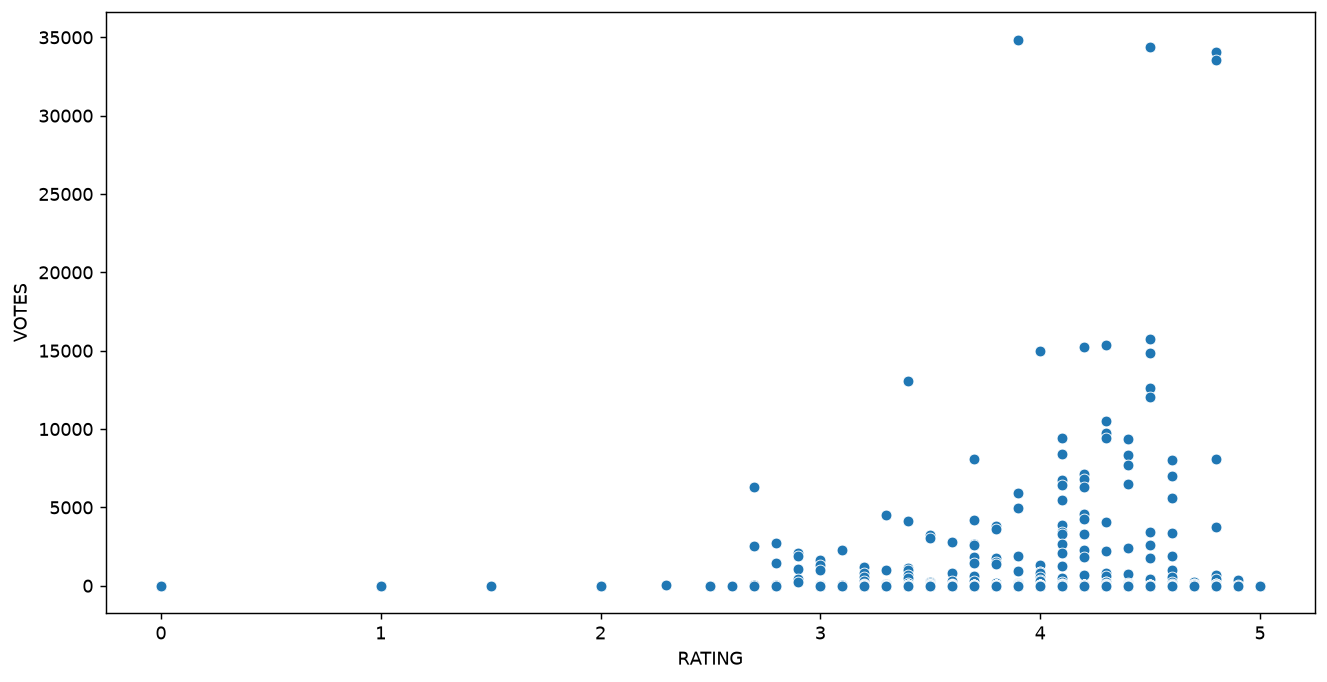

In [5]:
plt.figure(figsize=(12,6), dpi=130)
sns.scatterplot(data=fandango, x='RATING', y='VOTES');

In [6]:
fandango.corr(numeric_only=True)

,STARS,RATING,VOTES
STARS,1.000000,0.994696,0.164218
RATING,0.994696,1.000000,0.163764
VOTES,0.164218,0.163764,1.000000


The `FILM` column has the format "Title (Year)", so the year can be extracted from the last word.

In [7]:
def parseYear(s):
    return s.split(' ')[-1].strip('()')

In [8]:
fandango['YEAR'] = fandango['FILM'].apply(parseYear)
fandango['YEAR'].value_counts()

YEAR
2015    478
2014     23
2016      1
1964      1
2012      1
Name: count, dtype: int64

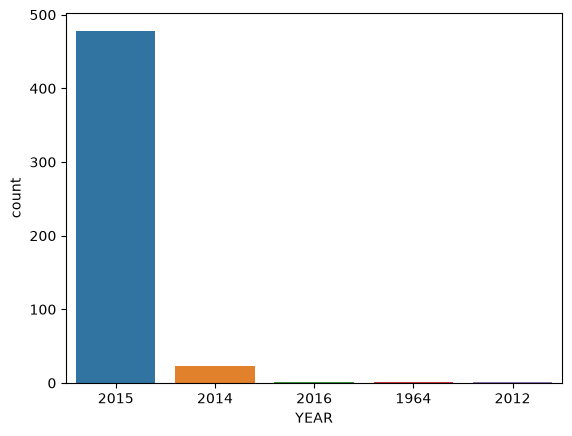

In [9]:
sns.countplot(data=fandango, x='YEAR', hue='YEAR');

Top 10 films by number of votes:

In [10]:
fandango.sort_values('VOTES', ascending=False).head(10)

,FILM,STARS,RATING,VOTES,YEAR
0,Fifty Shades of Grey (2015),4.0,3.9,34846,2015
1,Jurassic World (2015),4.5,4.5,34390,2015
2,American Sniper (2015),5.0,4.8,34085,2015
3,Furious 7 (2015),5.0,4.8,33538,2015
4,Inside Out (2015),4.5,4.5,15749,2015
5,The Hobbit: The Battle of the Five Armies (2014),4.5,4.3,15337,2014
6,Kingsman: The Secret Service (2015),4.5,4.2,15205,2015
7,Minions (2015),4.0,4.0,14998,2015
8,Avengers: Age of Ultron (2015),5.0,4.5,14846,2015
9,Into the Woods (2014),3.5,3.4,13055,2014


Films with zero votes are removed, since their rating carries no information.

In [11]:
fandango['VOTES'].value_counts()[0]

np.int64(69)

In [12]:
fandango = fandango[fandango['VOTES'] > 0]
fandango.shape

(435, 5)

### Displayed stars vs. actual rating

`STARS` is what users see, `RATING` is the real average. If the difference is always non-negative, Fandango rounds up.

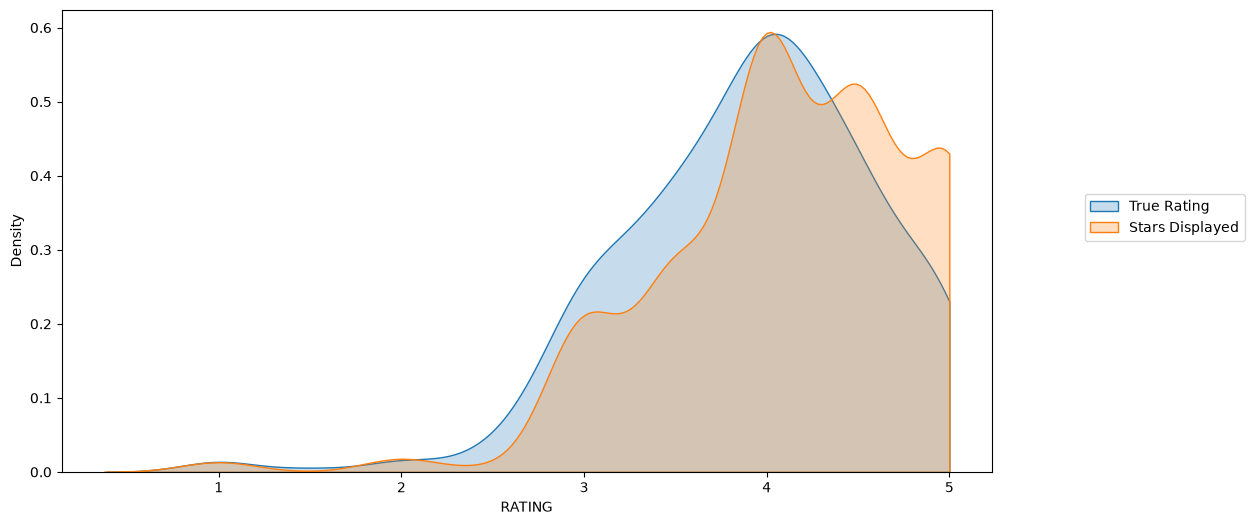

In [13]:
plt.figure(figsize=(12,6))
sns.kdeplot(data=fandango, x='RATING', fill=True, label='True Rating', clip=(0,5))
sns.kdeplot(data=fandango, x='STARS', fill=True, label='Stars Displayed', clip=(0,5))
plt.legend(loc=(1.1,0.5));

In [14]:
fandango['STARS_DIFF'] = (fandango['STARS'] - fandango['RATING']).round(1)
fandango.head()

,FILM,STARS,RATING,VOTES,YEAR,STARS_DIFF
0,Fifty Shades of Grey (2015),4.0,3.9,34846,2015,0.1
1,Jurassic World (2015),4.5,4.5,34390,2015,0.0
2,American Sniper (2015),5.0,4.8,34085,2015,0.2
3,Furious 7 (2015),5.0,4.8,33538,2015,0.2
4,Inside Out (2015),4.5,4.5,15749,2015,0.0


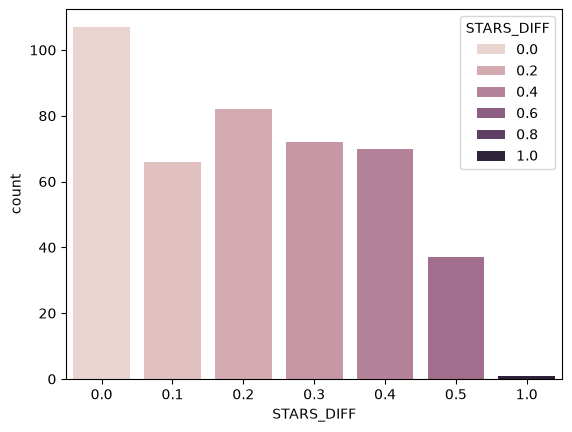

In [15]:
sns.countplot(data=fandango, x='STARS_DIFF', hue='STARS_DIFF');

In [16]:
fandango['FILM'][fandango['STARS_DIFF'] == 1]

381    Turbo Kid (2015)
Name: FILM, dtype: str

In [17]:
print('Mean STARS - RATING:', fandango['STARS_DIFF'].mean().round(2))
print('Share of films with STARS > RATING:', (fandango['STARS_DIFF'] > 0).mean().round(2))
print('Share of films with STARS < RATING:', (fandango['STARS_DIFF'] < 0).mean().round(2))

Mean STARS - RATING: 0.21
Share of films with STARS > RATING: 0.75
Share of films with STARS < RATING: 0.0


### Other sites

In [18]:
all_sites = pd.read_csv('data/all_sites_scores.csv')
all_sites.head()

,FILM,RottenTomatoes,RottenTomatoes_User,Metacritic,Metacritic_User,IMDB,Metacritic_user_vote_count,IMDB_user_vote_count
0,Avengers: Age of Ultron (2015),74,86,66,7.1,7.8,1330,271107
1,Cinderella (2015),85,80,67,7.5,7.1,249,65709
2,Ant-Man (2015),80,90,64,8.1,7.8,627,103660
3,Do You Believe? (2015),18,84,22,4.7,5.4,31,3136
4,Hot Tub Time Machine 2 (2015),14,28,29,3.4,5.1,88,19560


In [19]:
all_sites.info()

<class 'pandas.DataFrame'>
RangeIndex: 146 entries, 0 to 145
Data columns (total 8 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   FILM                        146 non-null    str    
 1   RottenTomatoes              146 non-null    int64  
 2   RottenTomatoes_User         146 non-null    int64  
 3   Metacritic                  146 non-null    int64  
 4   Metacritic_User             146 non-null    float64
 5   IMDB                        146 non-null    float64
 6   Metacritic_user_vote_count  146 non-null    int64  
 7   IMDB_user_vote_count        146 non-null    int64  
dtypes: float64(2), int64(5), str(1)
memory usage: 9.3 KB


In [20]:
all_sites.describe()

,RottenTomatoes,RottenTomatoes_User,Metacritic,Metacritic_User,IMDB,Metacritic_user_vote_count,IMDB_user_vote_count
count,146.000000,146.000000,146.000000,146.000000,146.000000,146.000000,146.000000
mean,60.849315,63.876712,58.808219,6.519178,6.736986,185.705479,42846.205479
std,30.168799,20.024430,19.517389,1.510712,0.958736,316.606515,67406.509171
min,5.000000,20.000000,13.000000,2.400000,4.000000,4.000000,243.000000
25%,31.250000,50.000000,43.500000,5.700000,6.300000,33.250000,5627.000000
50%,63.500000,66.500000,59.000000,6.850000,6.900000,72.500000,19103.000000
75%,89.000000,81.000000,75.000000,7.500000,7.400000,168.500000,45185.750000
max,100.000000,94.000000,94.000000,9.600000,8.600000,2375.000000,334164.000000


**Rotten Tomatoes.** `Rotten_Diff` = critics score minus users score: positive means critics liked the film more than users.

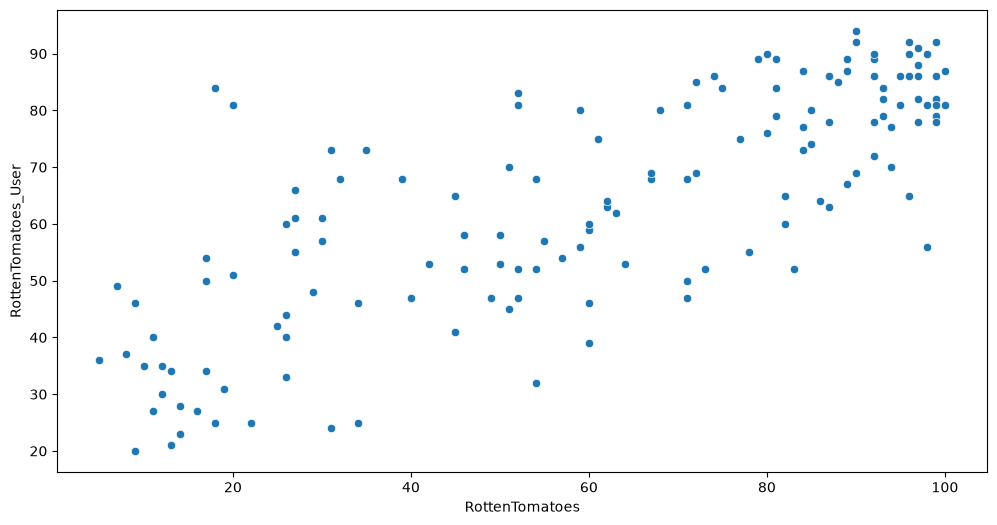

In [21]:
plt.figure(figsize=(12,6))
sns.scatterplot(data=all_sites, x='RottenTomatoes', y='RottenTomatoes_User');

In [22]:
all_sites['Rotten_Diff'] = all_sites['RottenTomatoes'] - all_sites['RottenTomatoes_User']
abs(all_sites['Rotten_Diff']).mean()

np.float64(15.095890410958905)

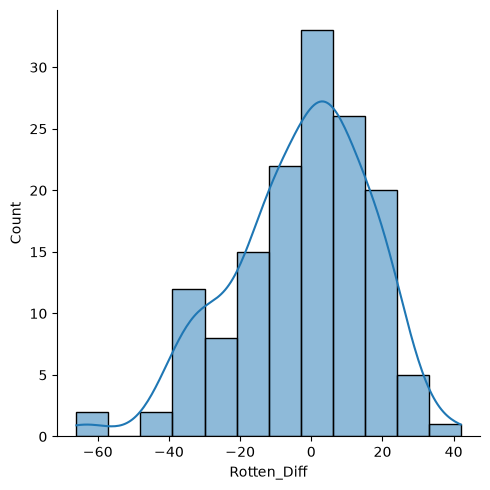

In [23]:
sns.displot(data=all_sites, x='Rotten_Diff', kde=True);

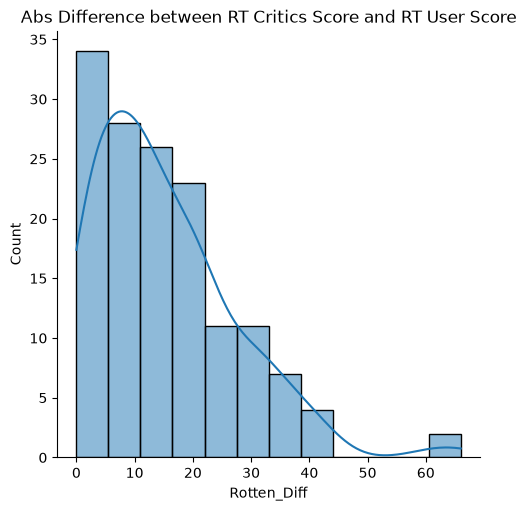

In [24]:
sns.displot(data=all_sites, x=abs(all_sites['Rotten_Diff']), kde=True)
plt.title('Abs Difference between RT Critics Score and RT User Score');

Films users liked much more than critics, and vice versa:

In [25]:
all_sites.sort_values('Rotten_Diff')[['FILM', 'Rotten_Diff']][:5]

,FILM,Rotten_Diff
3,Do You Believe? (2015),-66
85,Little Boy (2015),-61
134,The Longest Ride (2015),-42
105,Hitman: Agent 47 (2015),-42
125,The Wedding Ringer (2015),-39


In [26]:
all_sites.sort_values('Rotten_Diff', ascending=False)[['FILM', 'Rotten_Diff']][:5]

,FILM,Rotten_Diff
69,Mr. Turner (2014),42
112,It Follows (2015),31
115,While We're Young (2015),31
145,"Kumiko, The Treasure Hunter (2015)",24
37,Welcome to Me (2015),24


**Metacritic and IMDb.**

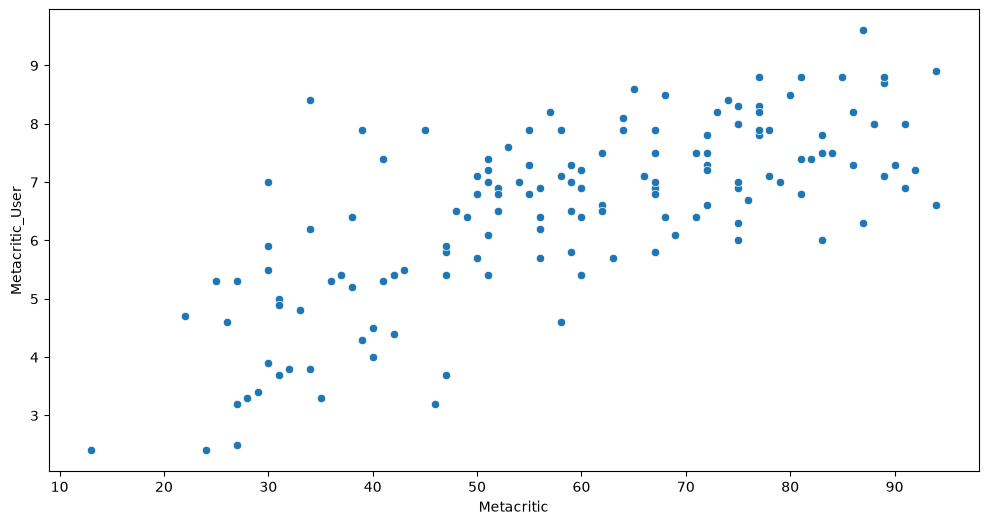

In [27]:
plt.figure(figsize=(12,6))
sns.scatterplot(data=all_sites, x='Metacritic', y='Metacritic_User');

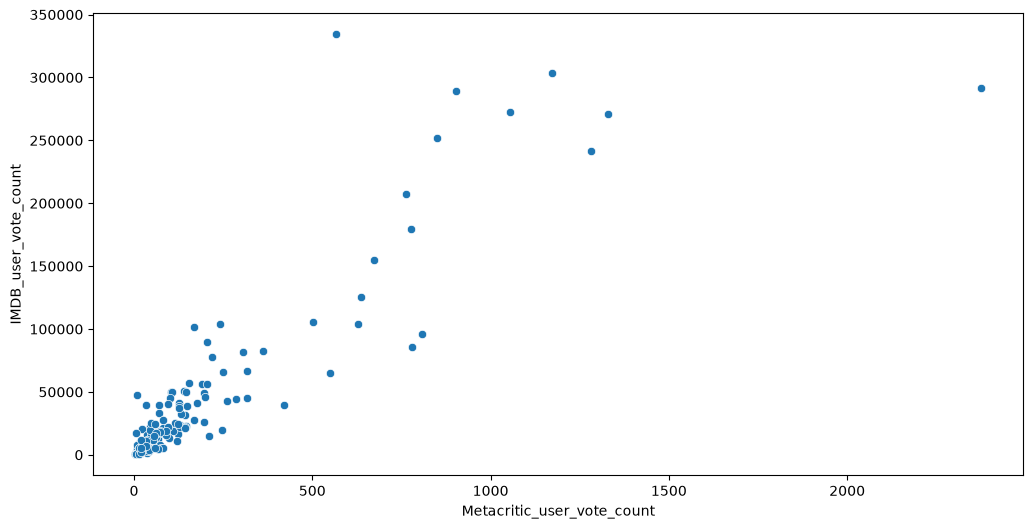

In [28]:
plt.figure(figsize=(12,6))
sns.scatterplot(data=all_sites, x='Metacritic_user_vote_count', y='IMDB_user_vote_count');

The two outliers: the film with the most IMDb votes (but few Metacritic votes) and the film with the most Metacritic votes.

In [29]:
all_sites[(all_sites['IMDB_user_vote_count'] == all_sites['IMDB_user_vote_count'].max()) & (all_sites['Metacritic_user_vote_count'] <= 599)]

,FILM,RottenTomatoes,RottenTomatoes_User,Metacritic,Metacritic_User,IMDB,Metacritic_user_vote_count,IMDB_user_vote_count,Rotten_Diff
14,The Imitation Game (2014),90,92,73,8.2,8.1,566,334164,-2


In [30]:
all_sites[all_sites['Metacritic_user_vote_count'] == all_sites['Metacritic_user_vote_count'].max()]

,FILM,RottenTomatoes,RottenTomatoes_User,Metacritic,Metacritic_User,IMDB,Metacritic_user_vote_count,IMDB_user_vote_count,Rotten_Diff
88,Mad Max: Fury Road (2015),97,88,89,8.7,8.3,2375,292023,9


## Preprocessing

The two tables are joined with an inner merge on `FILM`, so only films present in both are compared. Then all scores are rescaled to Fandango's 0-5 range: 100-point scores are divided by 20 and 10-point scores by 2.

In [31]:
all_sites_and_fandango = pd.merge(fandango, all_sites, on='FILM', how='inner')
all_sites_and_fandango.info()

<class 'pandas.DataFrame'>
RangeIndex: 145 entries, 0 to 144
Data columns (total 14 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   FILM                        145 non-null    str    
 1   STARS                       145 non-null    float64
 2   RATING                      145 non-null    float64
 3   VOTES                       145 non-null    int64  
 4   YEAR                        145 non-null    str    
 5   STARS_DIFF                  145 non-null    float64
 6   RottenTomatoes              145 non-null    int64  
 7   RottenTomatoes_User         145 non-null    int64  
 8   Metacritic                  145 non-null    int64  
 9   Metacritic_User             145 non-null    float64
 10  IMDB                        145 non-null    float64
 11  Metacritic_user_vote_count  145 non-null    int64  
 12  IMDB_user_vote_count        145 non-null    int64  
 13  Rotten_Diff                 145 non-null    in

In [32]:
hundred = ['RottenTomatoes', 'RottenTomatoes_User', 'Metacritic']
tenth = ['Metacritic_User', 'IMDB']

all_sites_and_fandango[hundred] = all_sites_and_fandango[hundred] / 20
all_sites_and_fandango[tenth] = all_sites_and_fandango[tenth] / 2

In [33]:
cols = ['STARS', 'RATING', 'RottenTomatoes', 'RottenTomatoes_User', 'Metacritic', 'Metacritic_User', 'IMDB']

norm_scores = all_sites_and_fandango[cols]
norm_scores.head()

,STARS,RATING,RottenTomatoes,RottenTomatoes_User,Metacritic,Metacritic_User,IMDB
0,4.0,3.9,1.25,2.10,2.30,1.60,2.10
1,4.5,4.5,3.55,4.05,2.95,3.50,3.65
2,5.0,4.8,3.60,4.25,3.60,3.30,3.70
3,5.0,4.8,4.05,4.20,3.35,3.40,3.70
4,4.5,4.5,4.90,4.50,4.70,4.45,4.30


## Results

### Score distributions across sites

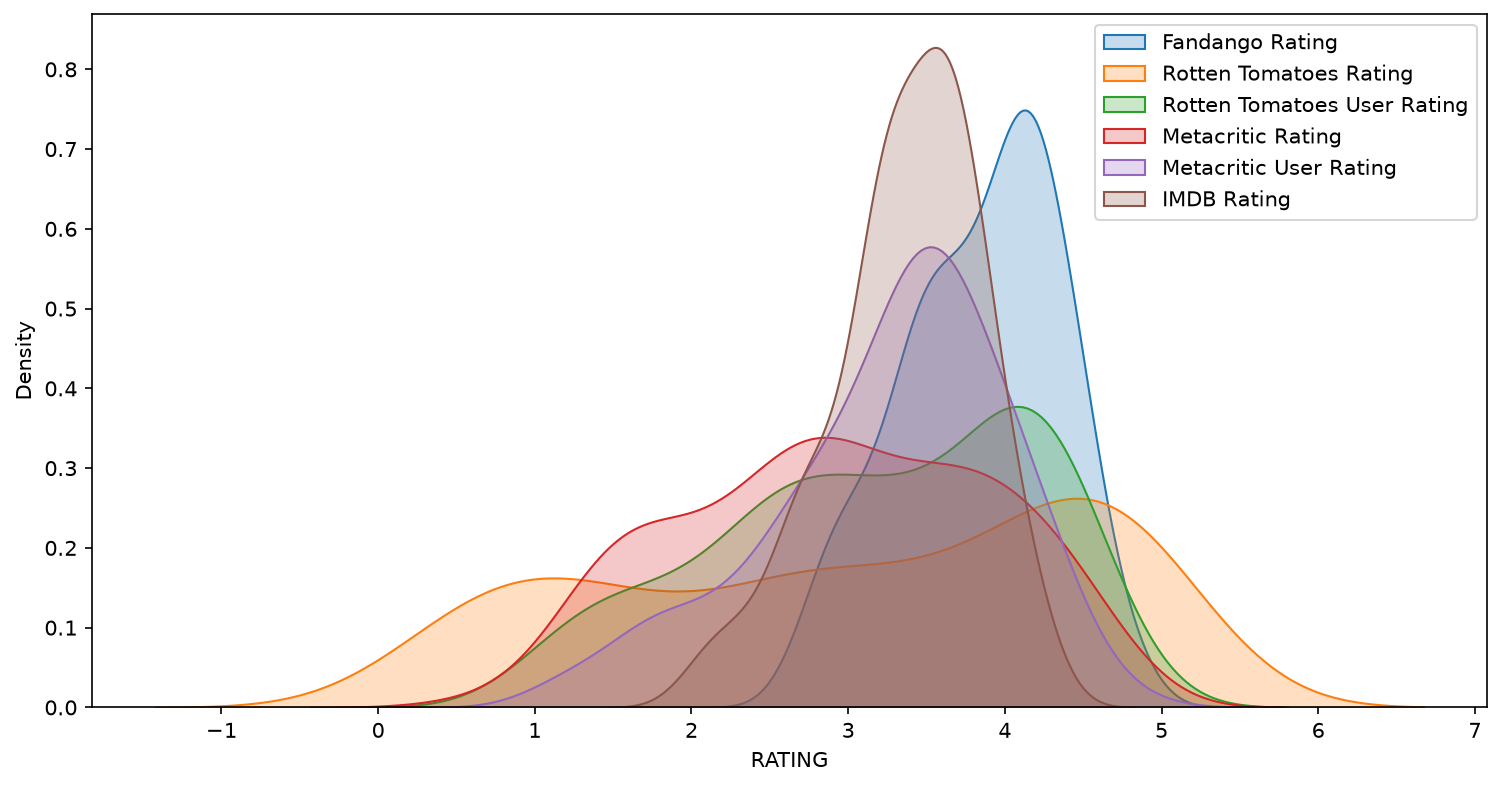

In [34]:
plt.figure(figsize=(12,6), dpi=150)

sns.kdeplot(data=norm_scores, x='RATING', fill=True, label='Fandango Rating')
sns.kdeplot(data=norm_scores, x='RottenTomatoes', fill=True, label='Rotten Tomatoes Rating')
sns.kdeplot(data=norm_scores, x='RottenTomatoes_User', fill=True, label='Rotten Tomatoes User Rating')
sns.kdeplot(data=norm_scores, x='Metacritic', fill=True, label='Metacritic Rating')
sns.kdeplot(data=norm_scores, x='Metacritic_User', fill=True, label='Metacritic User Rating')
sns.kdeplot(data=norm_scores, x='IMDB', fill=True, label='IMDB Rating')

plt.legend()
plt.savefig('images/score_distributions.png', bbox_inches='tight');

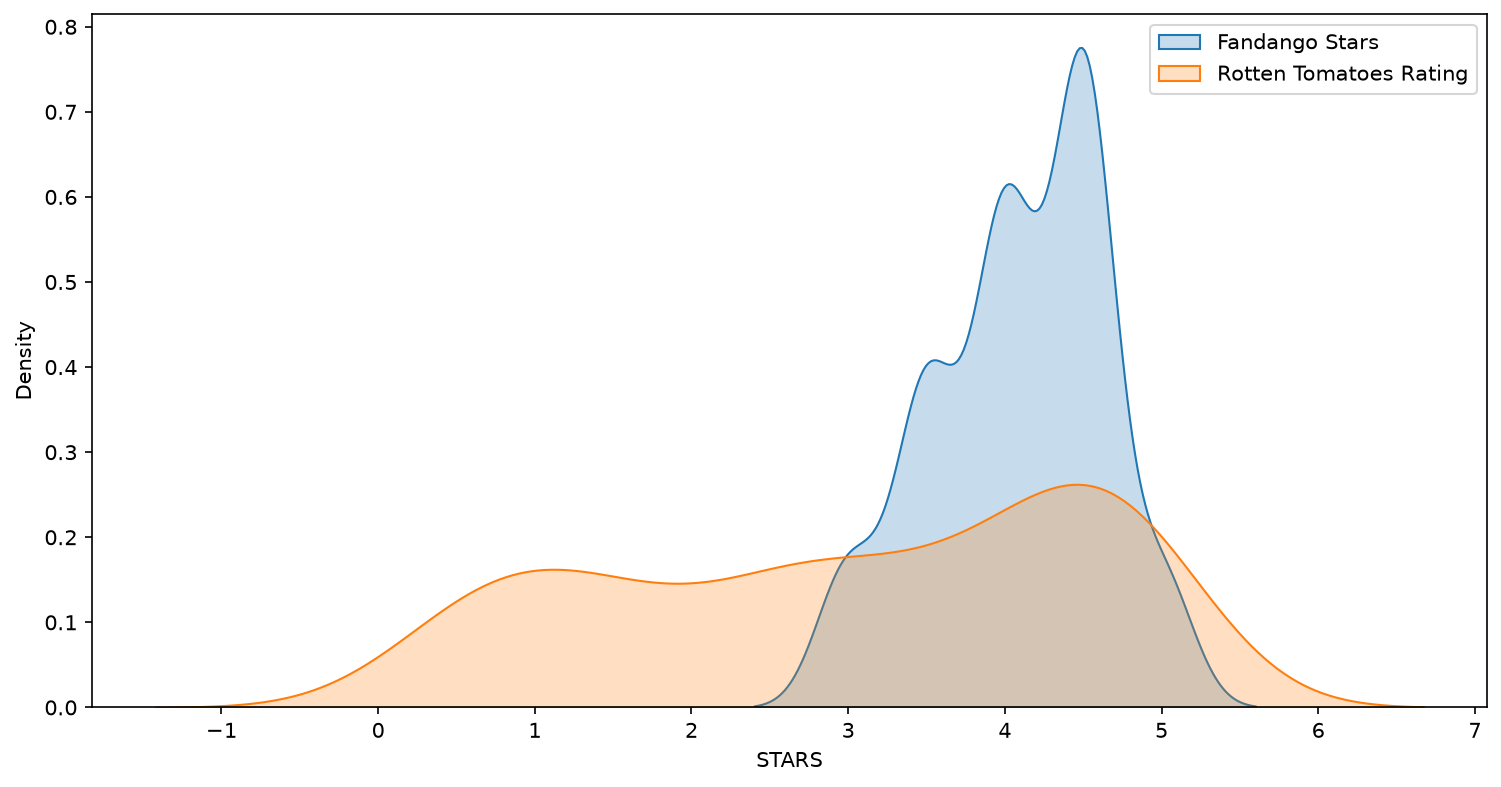

In [35]:
plt.figure(figsize=(12,6), dpi=150)

sns.kdeplot(data=norm_scores, x='STARS', fill=True, label='Fandango Stars')
sns.kdeplot(data=norm_scores, x='RottenTomatoes', fill=True, label='Rotten Tomatoes Rating')

plt.legend();

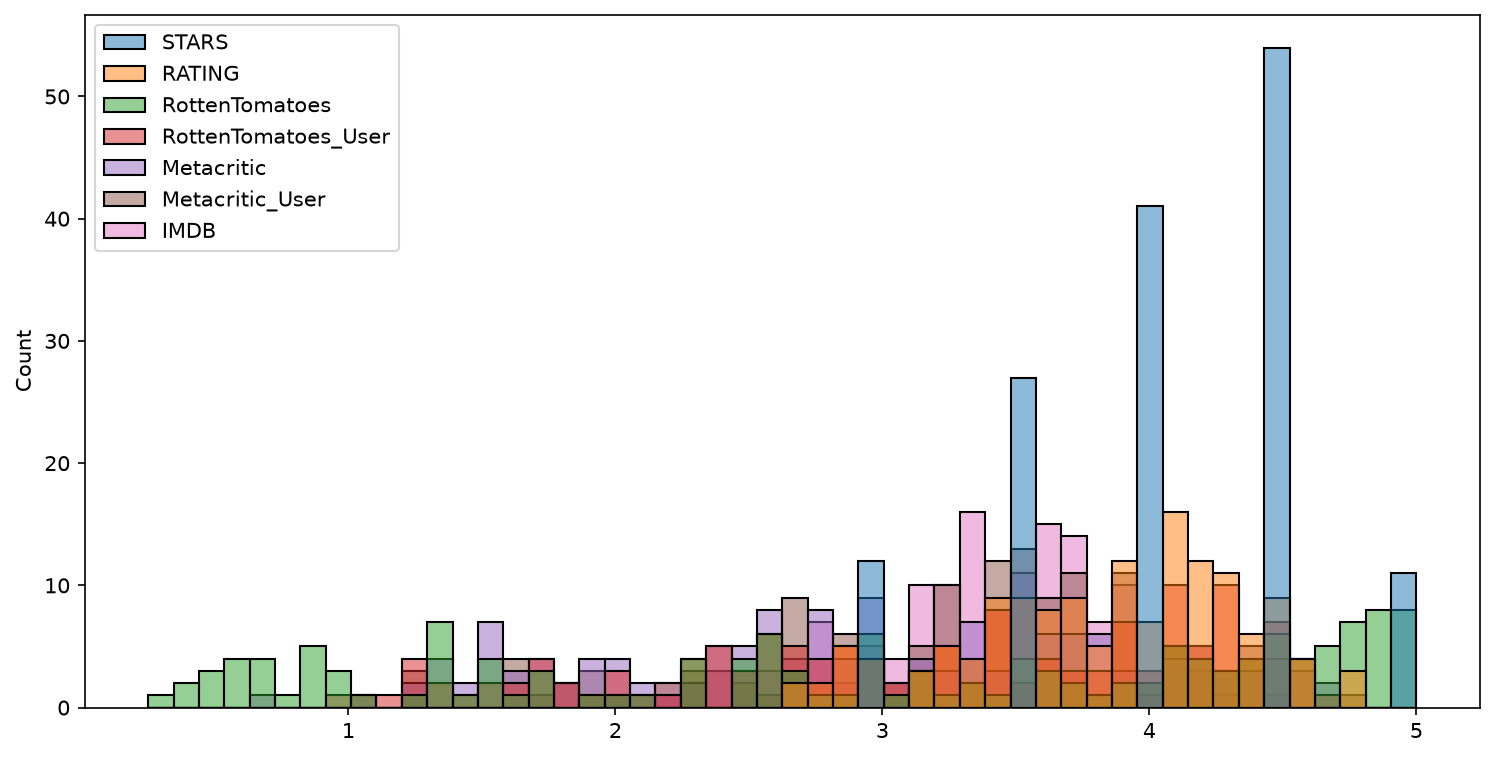

In [36]:
plt.figure(figsize=(12,6), dpi=150)
sns.histplot(data=norm_scores, bins=50);

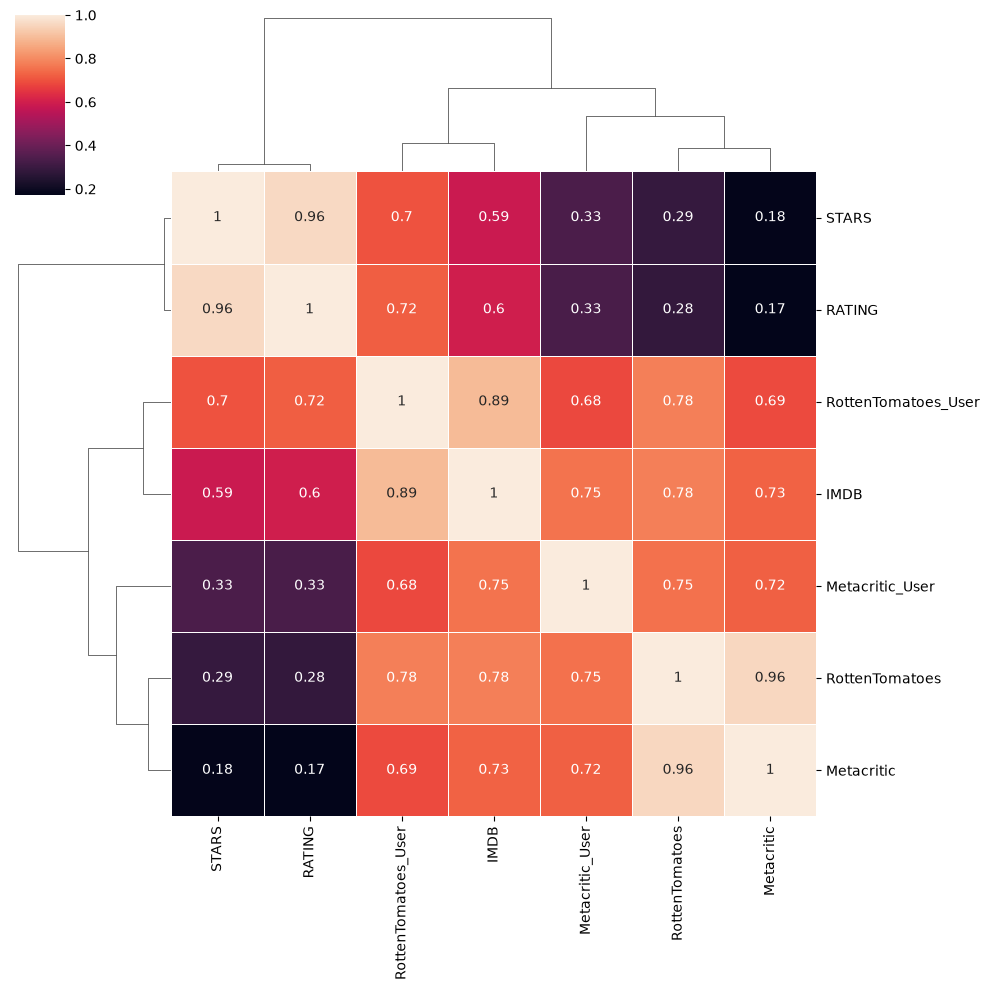

In [37]:
sns.clustermap(data=norm_scores.corr(), linewidth=0.5, annot=True);

Average normalized score per site (0-5 scale):

In [38]:
norm_scores.mean().sort_values(ascending=False).round(2)

STARS                  4.09
RATING                 3.84
IMDB                   3.36
Metacritic_User        3.25
RottenTomatoes_User    3.18
RottenTomatoes         3.03
Metacritic             2.93
dtype: float64

### The worst-rated films

The 10 films with the lowest Rotten Tomatoes critics score and how each site rated them.

In [39]:
worst_movies = all_sites_and_fandango.sort_values('RottenTomatoes')[:10]
worst_movies[['FILM'] + cols]

,FILM,STARS,RATING,RottenTomatoes,RottenTomatoes_User,Metacritic,Metacritic_User,IMDB
49,Paul Blart: Mall Cop 2 (2015),3.5,3.5,0.25,1.80,0.65,1.20,2.15
84,Hitman: Agent 47 (2015),4.0,3.9,0.35,2.45,1.40,1.65,2.95
54,Hot Pursuit (2015),4.0,3.7,0.40,1.85,1.55,1.85,2.45
25,Taken 3 (2015),4.5,4.1,0.45,2.30,1.30,2.30,3.05
28,Fantastic Four (2015),3.0,2.7,0.45,1.00,1.35,1.25,2.00
50,The Boy Next Door (2015),4.0,3.6,0.50,1.75,1.50,2.75,2.30
88,The Loft (2015),4.0,3.6,0.55,2.00,1.20,1.20,3.15
87,Unfinished Business (2015),3.5,3.2,0.55,1.35,1.60,1.90,2.70
78,Mortdecai (2015),3.5,3.2,0.60,1.50,1.35,1.60,2.75
77,Seventh Son (2015),3.5,3.2,0.60,1.75,1.50,1.95,2.75


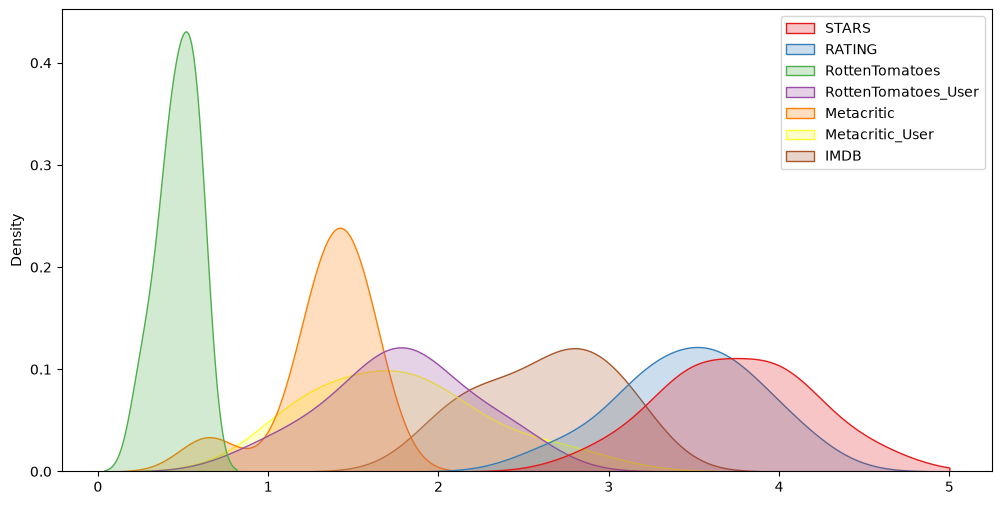

In [40]:
plt.figure(figsize=(12,6))
sns.kdeplot(data=worst_movies[cols], clip=[0,5], palette='Set1', fill=True)
plt.savefig('images/worst_movies.png', bbox_inches='tight');

Among these ten films the largest gap is *Taken 3*: 4.5 stars on Fandango versus the average of the other sites:

In [41]:
other_sites = ['RottenTomatoes', 'RottenTomatoes_User', 'Metacritic', 'Metacritic_User', 'IMDB']
taken3 = all_sites_and_fandango[all_sites_and_fandango['FILM'] == 'Taken 3 (2015)']
taken3[cols]

,STARS,RATING,RottenTomatoes,RottenTomatoes_User,Metacritic,Metacritic_User,IMDB
25,4.5,4.1,0.45,2.3,1.3,2.3,3.05


In [42]:
taken3[other_sites].mean(axis=1).round(2)

25    1.88
dtype: float64

## Conclusions

**Are Fandango ratings inflated compared to other sites? Yes.** On the 145 films present in both tables, Fandango's displayed stars average 4.09 out of 5, while the other sites average between 2.93 (Metacritic critics) and 3.36 (IMDb). Even Fandango's own underlying rating (3.84) is higher than every other site. On top of that, the displayed stars are never lower than the real rating: they are rounded up for 75% of films, by 0.21 stars on average and by a full star for *Turbo Kid*. The gap is largest for bad films: *Taken 3* shows 4.5 stars on Fandango but averages 1.88 on the other sites.